# Assignment 5: Evaluation Beyond Accuracy

## Domain
Education

## Problem Statement
Identify students who may be at risk of failing based on
their demographic, family background, and study-related features.

## Classification
Binary Classification

## Target
G3 < 10 = At Risk (1)
G3 >= 10 = Not At Risk (0)

## Positive Class
At Risk students

## Models
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

In [1]:
!wget -q https://archive.ics.uci.edu/static/public/320/student+performance.zip -O student.zip
!mkdir -p student_data
!unzip -oq student.zip -d student_data

In [3]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content
Files: ['.config', 'student.zip', 'student_data', 'sample_data']


In [4]:
print(os.listdir("student_data"))

['student.zip', '.student.zip_old']


In [6]:
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv


In [8]:
import os
import zipfile
import urllib.request
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download dataset
urllib.request.urlretrieve(url, "/content/student_performance.zip")

# Create a fresh extraction folder
folder = Path("/content/student_data")
folder.mkdir(exist_ok=True)

# Extract the downloaded ZIP
with zipfile.ZipFile("/content/student_performance.zip", "r") as z:
    z.extractall(folder)

# Extract any nested ZIP files
for zip_path in folder.rglob("*.zip"):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(folder)

# Find CSV files
csv_files = list(folder.rglob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/content/student_data/student-por.csv
/content/student_data/student-mat.csv


In [9]:
csv_path = next(
    file for file in csv_files
    if file.name == "student-por.csv"
)

df = pd.read_csv(csv_path, sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [10]:
# 1 = At Risk, 0 = Not At Risk
df["At_Risk"] = (df["G3"] < 10).astype(int)

print(df["At_Risk"].value_counts())
print("\nClass distribution:")
print(df["At_Risk"].value_counts(normalize=True) * 100)

At_Risk
0    549
1    100
Name: count, dtype: int64

Class distribution:
At_Risk
0    84.59168
1    15.40832
Name: proportion, dtype: float64


In [11]:
X = df.drop(columns=["G3", "G1", "G2", "At_Risk"])
y = df["At_Risk"]

print("Features:", X.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts())

Features: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Target distribution:
At_Risk
0    549
1    100
Name: count, dtype: int64


In [12]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 519
Testing rows: 130


In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

pipelines = {}

for name, classifier in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", classifier)
    ])

    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


In [16]:
model = pipelines["Logistic Regression"]

predictions = model.predict(X_test)

cm = confusion_matrix(y_test, predictions, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[107   3]
 [ 17   3]]

True Negatives: 107
False Positives: 3
False Negatives: 17
True Positives: 3


In [17]:
print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, zero_division=0))
print("Recall:", recall_score(y_test, predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, predictions, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

Accuracy: 0.8461538461538461
Precision: 0.5
Recall: 0.15
F1 Score: 0.23076923076923078

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.97      0.91       110
           1       0.50      0.15      0.23        20

    accuracy                           0.85       130
   macro avg       0.68      0.56      0.57       130
weighted avg       0.81      0.85      0.81       130



In [18]:
for name, pipe in pipelines.items():

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    print("\n", name)
    print("Fold Scores:", scores)
    print("Mean F1:", scores.mean().round(3))
    print("Standard Deviation:", scores.std().round(3))


 Logistic Regression
Fold Scores: [0.56       0.5        0.37037037 0.27272727 0.36363636]
Mean F1: 0.413
Standard Deviation: 0.103

 Decision Tree
Fold Scores: [0.4375     0.42105263 0.47058824 0.3030303  0.45714286]
Mean F1: 0.418
Standard Deviation: 0.06

 Random Forest
Fold Scores: [0.22222222 0.2        0.31578947 0.28571429 0.        ]
Mean F1: 0.205
Standard Deviation: 0.111


In [19]:
results = []

for name, pipe in pipelines.items():

    pred = pipe.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

evaluation_df = pd.DataFrame(results)

evaluation_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.846,0.500,0.15,0.231
1,Decision Tree,0.815,0.357,0.25,0.294
2,Random Forest,0.854,0.571,0.20,0.296


## Domain-Specific Error Analysis

In this educational use case, a false negative is more harmful
than a false positive.

A false negative means that an actually at-risk student is
classified as not at risk. This may prevent the student from
receiving timely academic support.

A false positive means that a student who is not at risk is
incorrectly flagged. This may result in unnecessary monitoring
or additional support.

Therefore, recall is particularly important because we want
to identify as many at-risk students as possible.

Confusion Matrix:
[[101   9]
 [ 15   5]]

True Negatives: 101
False Positives: 9
False Negatives: 15
True Positives: 5


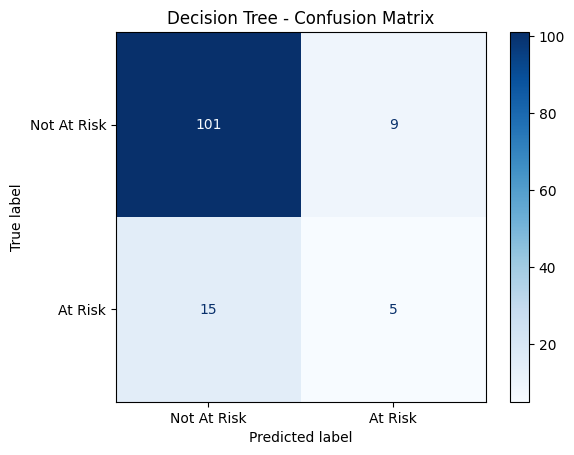

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

dt_model = pipelines["Decision Tree"]

dt_predictions = dt_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    dt_predictions,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not At Risk", "At Risk"]
).plot(cmap="Blues")

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [22]:
cv_results = []

for name, pipe in pipelines.items():

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    cv_results.append({
        "Model": name,
        "Fold Scores": scores.round(3).tolist(),
        "Mean F1": scores.mean(),
        "Std Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.round(3)

,Model,Fold Scores,Mean F1,Std Deviation
0,Logistic Regression,"[0.56, 0.5, 0.37, 0.273, 0.364]",0.413,0.103
1,Decision Tree,"[0.438, 0.421, 0.471, 0.303, 0.457]",0.418,0.060
2,Random Forest,"[0.222, 0.2, 0.316, 0.286, 0.0]",0.205,0.111


## Model Recommendation

The Decision Tree Classifier is the recommended model for this experiment because it achieved the highest cross-validation mean F1-score of 0.418 and the highest recall of 0.25 among the three models on the test set.

However, its recall is still low, identifying only 5 out of 20 students who were actually at risk, while missing 15 students.

Therefore, although the Decision Tree performed best overall in this experiment, it needs further improvement before being considered reliable for an educational early-warning system.